## Dataset

In [ ]:
from sklearn.datasets import fetch_california_housing
import pandas as pd

# Load dataset as a Pandas DataFrame
california = fetch_california_housing(as_frame=True)
df = california.frame

# Display the first 5 rows to inspect the features
display(df.head())

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## California Housing Price Model

In [ ]:
pip install scikit-optimize

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [scikit-optimize]


Loading California Housing dataset...

--- Running Model Evaluation Loop ---


'[Simple LR (Custom)] MSE: 0.7091 | RMSE: 0.8421 | MAE: 0.6299 | MAPE: 0.3906 | R²: 0.4589 | Adj R²: 0.4587'

'[Simple LR (sklearn)] MSE: 0.7091 | RMSE: 0.8421 | MAE: 0.6299 | MAPE: 0.3906 | R²: 0.4589 | Adj R²: 0.4587'

'[Multiple LR] MSE: 0.5559 | RMSE: 0.7456 | MAE: 0.5332 | MAPE: 0.3195 | R²: 0.5758 | Adj R²: 0.5750'

'[Polynomial LR (deg=2)] MSE: 0.4643 | RMSE: 0.6814 | MAE: 0.4670 | MAPE: 0.2690 | R²: 0.6457 | Adj R²: 0.6419'

'[Lasso (cyclic)] MSE: 0.5483 | RMSE: 0.7404 | MAE: 0.5353 | MAPE: 0.3201 | R²: 0.5816 | Adj R²: 0.5808'

... (4 outputs left out)

'[ElasticNet] MSE: 0.5500 | RMSE: 0.7416 | MAE: 0.5341 | MAPE: 0.3194 | R²: 0.5803 | Adj R²: 0.5795'

'[ElasticNetCV] MSE: 0.5544 | RMSE: 0.7446 | MAE: 0.5331 | MAPE: 0.3193 | R²: 0.5770 | Adj R²: 0.5761'


--- Running Hyperparameter Optimization ---
Best Ridge Params (GridSearch): {'reg__alpha': 1.0, 'reg__solver': 'sag', 'reg__tol': 0.0001}
Best Lasso Params (RandomSearch): {'reg__alpha': np.float64(0.0059083612168199465), 'reg__selection': 'random'}
Best ElasticNet Params (Bayesian Optimization): OrderedDict({'reg__alpha': 0.0011233621690895233, 'reg__l1_ratio': 0.7277257431773251})


/tmp/ipykernel_1041/4176095787.py:251: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_1041/4176095787.py:251: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_1041/4176095787.py:251: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_1041/4176095787.py:251: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_1041/4176095787.py:251: FutureWarning

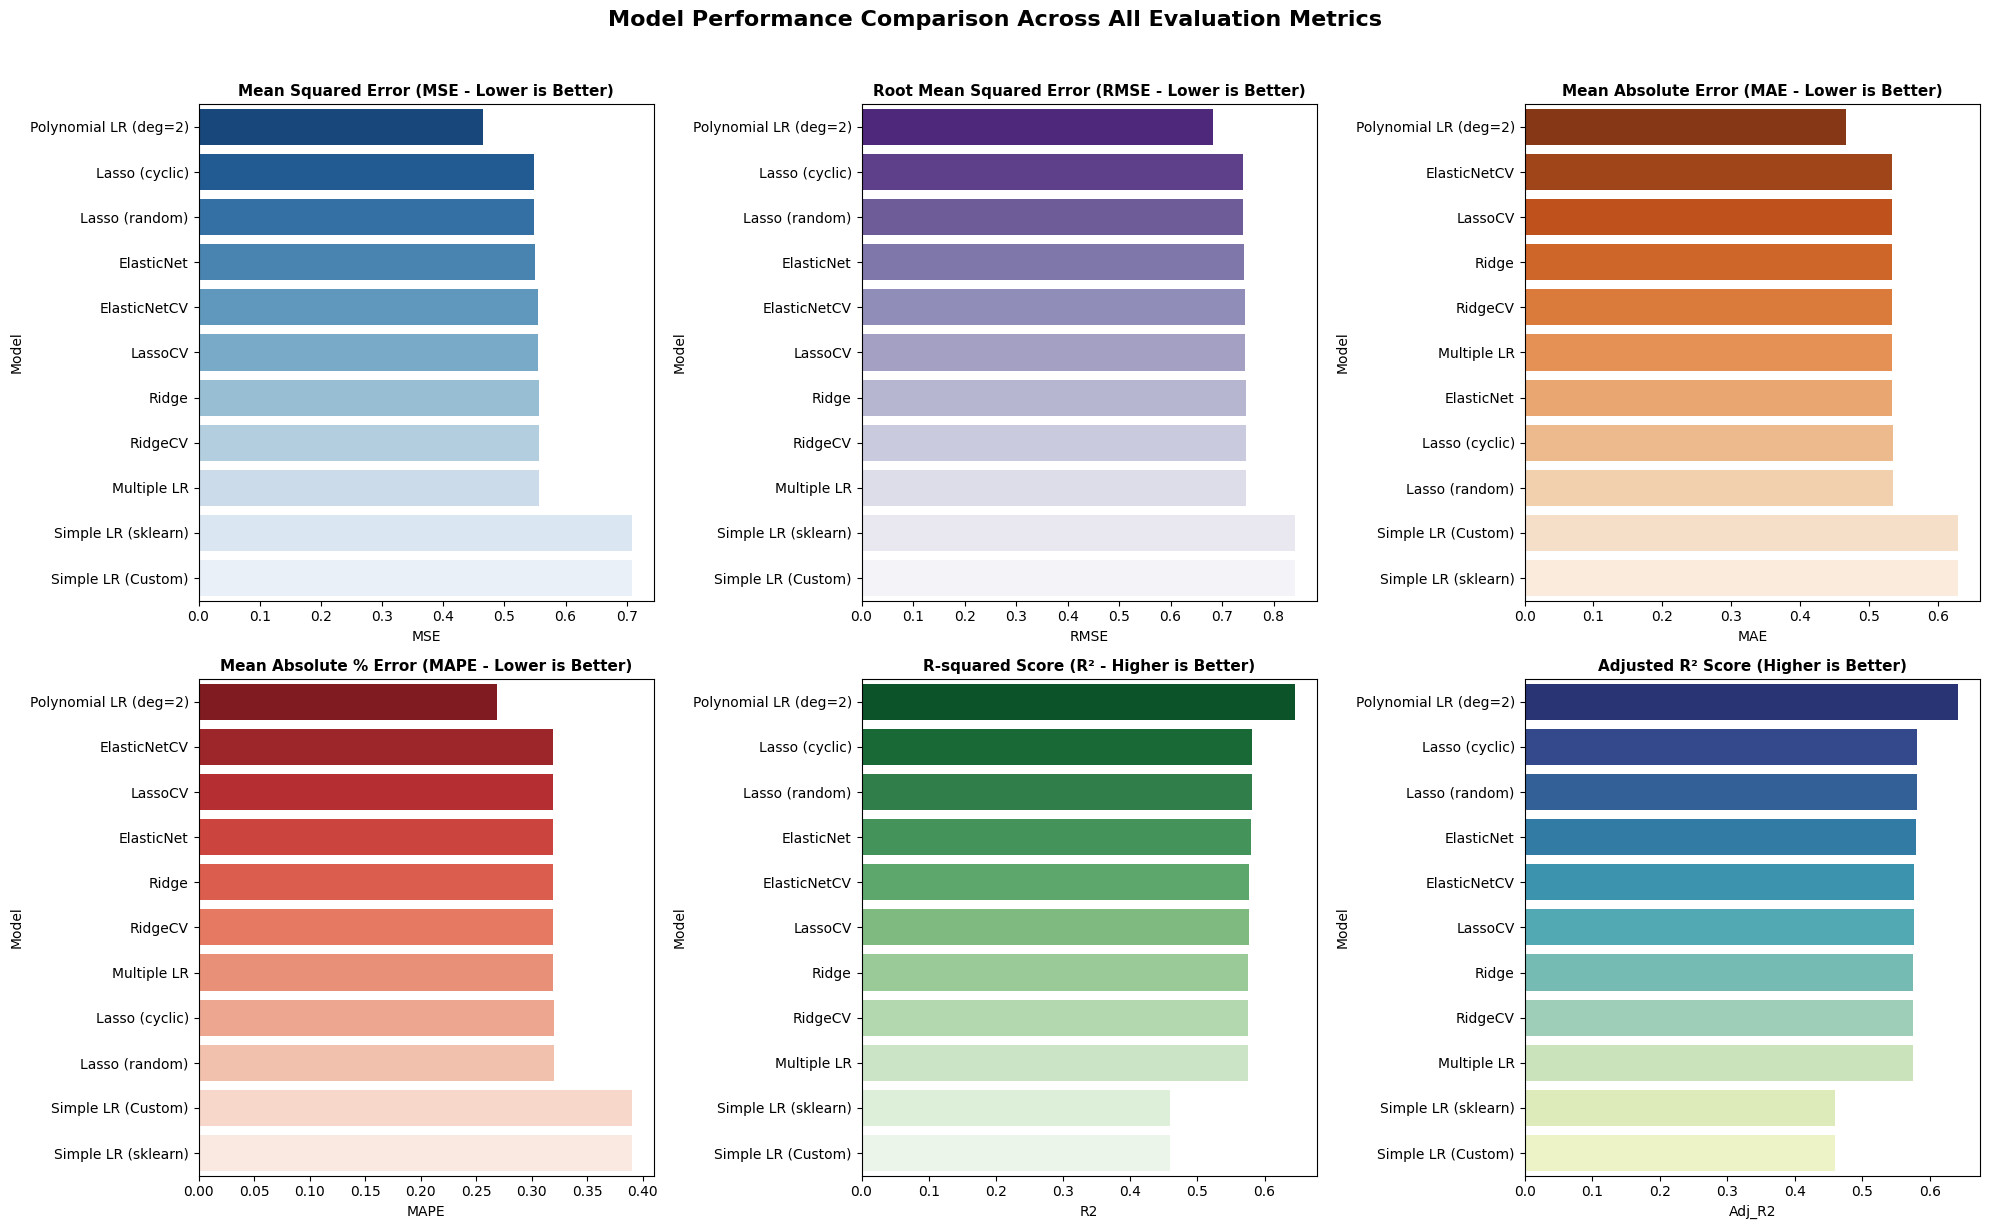

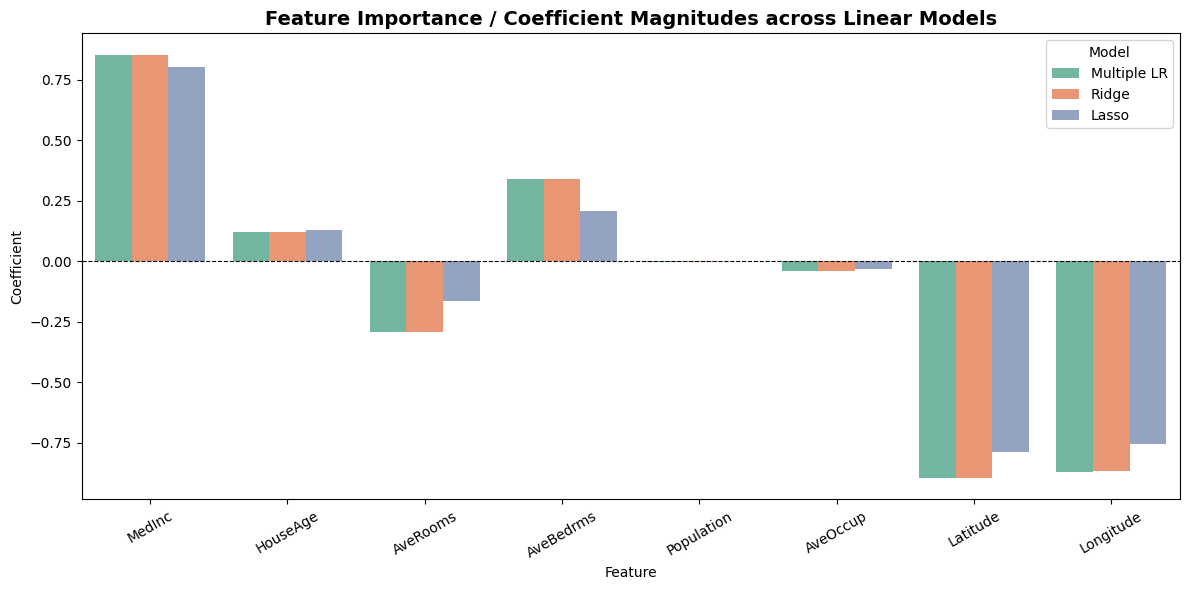

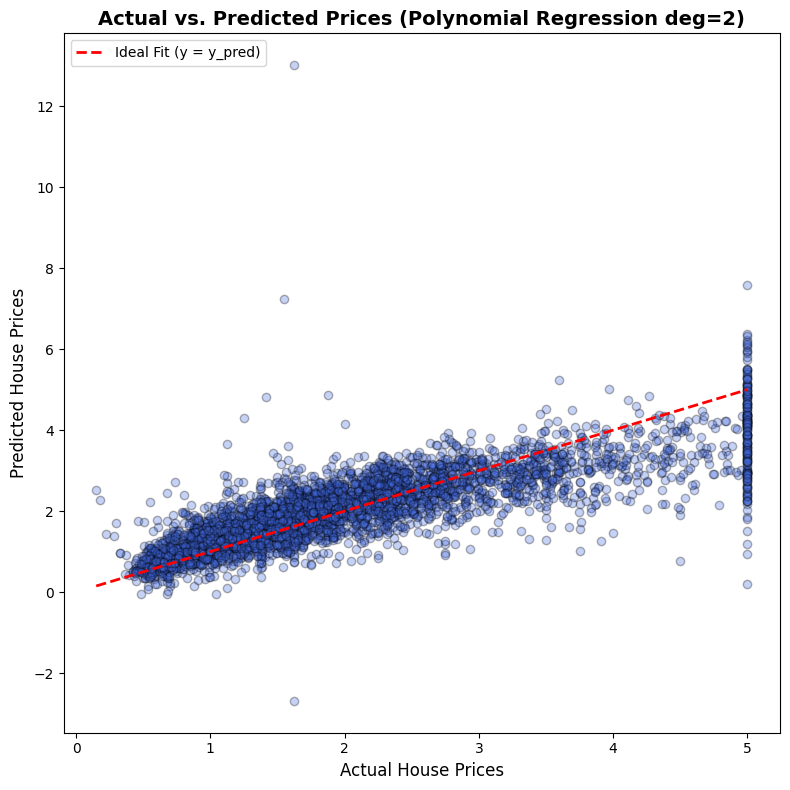

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, KFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import (
    LinearRegression,
    Lasso, LassoCV,
    Ridge, RidgeCV,
    ElasticNet, ElasticNetCV
)
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score
)

# =====================================================================
# 1. PROGRAMMATIC IMPLEMENTATION: CUSTOM SIMPLE LINEAR REGRESSION
# =====================================================================
class mySLR:
    """
    Custom Simple Linear Regression implemented using Ordinary Least Squares (OLS) closed-form solution.
    """
    def __init__(self):
        self.coef_ = None
        self.intercept_ = None

    def fit(self, X, y):
        X = np.array(X).flatten()
        y = np.array(y).flatten()

        x_mean = np.mean(X)
        y_mean = np.mean(y)

        numerator = np.sum((X - x_mean) * (y - y_mean))
        denominator = np.sum((X - x_mean) ** 2)

        self.coef_ = numerator / denominator
        self.intercept_ = y_mean - self.coef_ * x_mean
        return self

    def predict(self, X):
        X = np.array(X).flatten()
        return self.coef_ * X + self.intercept_


# =====================================================================
# 2. SVM MATHEMATICAL DERIVATION & SKLEARN DIFFERENCES REPORT
# =====================================================================
r"""
[SVM / SVR Mathematical Derivation Summary]
- Primal Optimization Problem:
  min (1/2)||w||^2 + C * sum(\xi_i + \xi_i*)
  Subject to: y_i - <w, x_i> - b <= \epsilon + \xi_i
              <w, x_i> + b - y_i <= \epsilon + \xi_i*
              \xi_i, \xi_i* >= 0
- Dual Formulation introduces Lagrange multipliers (\alpha, \alpha*) to solve via quadratic programming,
  incorporating kernel functions (e.g., RBF, Polynomial) to handle nonlinear data mapping.

[Custom vs. Scikit-learn (sklearn.svm.SVR) Differences]
- Scikit-learn's SVR relies on highly optimized C++ libsvm wrappers, handling sparse matrices,
  efficient memory allocation, and advanced SMO (Sequential Minimal Optimization) solvers.
- Writing a custom SVR from scratch requires implementing quadratic programming optimization solvers
  (like CVXOPT) and kernel matrix computations.
"""


# =====================================================================
# 3. CALIFORNIA HOUSING DATASET & MODEL EVALUATION LOOP
# =====================================================================
print("Loading California Housing dataset...")
data = fetch_california_housing(as_frame=True)
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# For custom Simple LR, select a single feature ('MedInc')
X_train_slr = X_train[['MedInc']]
X_test_slr = X_test[['MedInc']]

# Define all specified linear models in a unified dictionary/array
models = {
    "Simple LR (Custom)": "custom",
    "Simple LR (sklearn)": Pipeline([('scaler', StandardScaler()), ('reg', LinearRegression())]),
    "Multiple LR": Pipeline([('scaler', StandardScaler()), ('reg', LinearRegression())]),
    "Polynomial LR (deg=2)": Pipeline([
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
        ('scaler', StandardScaler()),
        ('reg', LinearRegression())
    ]),
    "Lasso (cyclic)": Pipeline([('scaler', StandardScaler()), ('reg', Lasso(alpha=0.01, selection='cyclic', random_state=42))]),
    "Lasso (random)": Pipeline([('scaler', StandardScaler()), ('reg', Lasso(alpha=0.01, selection='random', random_state=42))]),
    "LassoCV": Pipeline([('scaler', StandardScaler()), ('reg', LassoCV(cv=5, random_state=42))]),
    "Ridge": Pipeline([('scaler', StandardScaler()), ('reg', Ridge(alpha=1.0, tol=1e-4, solver='auto'))]),
    "RidgeCV": Pipeline([('scaler', StandardScaler()), ('reg', RidgeCV(alphas=[0.1, 1.0, 10.0], cv=5))]),
    "ElasticNet": Pipeline([('scaler', StandardScaler()), ('reg', ElasticNet(alpha=0.01, l1_ratio=0.5, random_state=42))]),
    "ElasticNetCV": Pipeline([('scaler', StandardScaler()), ('reg', ElasticNetCV(cv=5, random_state=42))])
}

results = []
predictions = {}
n = X_test.shape[0]  # Number of samples for Adjusted R²

print("\n--- Running Model Evaluation Loop ---")
for name, model in models.items():
    if name == "Simple LR (Custom)":
        custom_slr = mySLR()
        custom_slr.fit(X_train_slr, y_train)
        y_pred = custom_slr.predict(X_test_slr)
        p = 1
    elif name == "Simple LR (sklearn)":
        model.fit(X_train_slr, y_train)
        y_pred = model.predict(X_test_slr)
        p = 1
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        # Determine feature count (p) post-transformation for Adjusted R²
        if hasattr(model, 'named_steps') and 'poly' in model.named_steps:
            X_train_trans = model.named_steps['poly'].fit_transform(X_train)
            p = X_train_trans.shape[1]
        else:
            p = X_train.shape[1]

    predictions[name] = y_pred

    # Calculate All 6 Metrics
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    adj_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1)) if (n - p - 1) > 0 else r2

    results.append({
        "Model": name,
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "MAPE": mape,
        "R2": r2,
        "Adj_R2": adj_r2
    })
    display(f"[{name}] MSE: {mse:.4f} | RMSE: {rmse:.4f} | MAE: {mae:.4f} | MAPE: {mape:.4f} | R²: {r2:.4f} | Adj R²: {adj_r2:.4f}")

results_df = pd.DataFrame(results)


# =====================================================================
# 4. HYPERPARAMETER OPTIMIZATION & TUNING
# (GridSearch, RandomizedSearchCV, Bayesian Optimization)
# =====================================================================
print("\n--- Running Hyperparameter Optimization ---")
kf = KFold(n_splits=3, shuffle=True, random_state=42)

# ---------------------------------------------------------------------
# A. GRID SEARCH (Implementation in Ridge & Lasso)
# ---------------------------------------------------------------------
# Ridge Parameter Specification: tol, solver, alpha
ridge_pipeline = Pipeline([('scaler', StandardScaler()), ('reg', Ridge(random_state=42))])
ridge_grid_params = {
    'reg__alpha': [0.01, 0.1, 1.0, 10.0, 100.0],
    'reg__solver': ['auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga'],
    'reg__tol': [1e-4, 1e-3]
}

ridge_grid = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_grid_params,
    cv=kf,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)
ridge_grid.fit(X_train, y_train)
print(f"Best Ridge Params (GridSearch): {ridge_grid.best_params_}")


# ---------------------------------------------------------------------
# B. RANDOMIZED SEARCH (Implementation in Lasso)
# ---------------------------------------------------------------------
# Lasso Parameter Specification: selection ('cyclic', 'random'), alpha
from scipy.stats import uniform

lasso_rand = RandomizedSearchCV(
    estimator=Pipeline([('scaler', StandardScaler()), ('reg', Lasso(random_state=42))]),
    param_distributions={
        'reg__alpha': uniform(0.0001, 0.1),
        'reg__selection': ['cyclic', 'random']
    },
    n_iter=5,
    cv=kf,
    scoring='neg_mean_squared_error',
    random_state=42,
    n_jobs=-1
)
lasso_rand.fit(X_train, y_train)
print(f"Best Lasso Params (RandomSearch): {lasso_rand.best_params_}")


# ---------------------------------------------------------------------
# C. BAYESIAN OPTIMIZATION (Implementation in ElasticNet)
# ---------------------------------------------------------------------
# ElasticNet Parameter Specification: alpha, l1_ratio
try:
    from skopt import BayesSearchCV
    from skopt.space import Real

    elastic_bayes = BayesSearchCV(
        estimator=Pipeline([('scaler', StandardScaler()), ('reg', ElasticNet(random_state=42))]),
        search_spaces={
            'reg__alpha': Real(1e-5, 1.0, prior='log-uniform'),
            'reg__l1_ratio': Real(0.0, 1.0)
        },
        n_iter=10,
        cv=kf,
        scoring='neg_mean_squared_error',
        random_state=42,
        n_jobs=-1
    )
    elastic_bayes.fit(X_train, y_train)
    print(f"Best ElasticNet Params (Bayesian Optimization): {elastic_bayes.best_params_}")

except ImportError:
    print("\n[Note] 'scikit-optimize' is not installed. To run Bayesian Optimization, execute: pip install scikit-optimize")

# =====================================================================
# 5. COMPREHENSIVE VISUALIZATIONS
# =====================================================================

# VISUALIZATION 1: 6-Panel Performance Metrics Grid
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
metrics_list = [
    ("MSE", "Mean Squared Error (MSE - Lower is Better)", "Blues_r"),
    ("RMSE", "Root Mean Squared Error (RMSE - Lower is Better)", "Purples_r"),
    ("MAE", "Mean Absolute Error (MAE - Lower is Better)", "Oranges_r"),
    ("MAPE", "Mean Absolute % Error (MAPE - Lower is Better)", "Reds_r"),
    ("R2", "R-squared Score (R² - Higher is Better)", "Greens_r"),
    ("Adj_R2", "Adjusted R² Score (Higher is Better)", "YlGnBu_r")
]

for idx, (metric, title, palette) in enumerate(metrics_list):
    ax = axes[idx // 3, idx % 3]
    ascending = True if "Error" in title or metric in ["MSE", "RMSE", "MAE", "MAPE"] else False
    sns.barplot(
        x=metric,
        y="Model",
        data=results_df.sort_values(metric, ascending=ascending),
        ax=ax,
        palette=palette
    )
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel(metric)

plt.suptitle("Model Performance Comparison Across All Evaluation Metrics", fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


# VISUALIZATION 2: Feature Coefficients Comparison (Multiple LR vs Ridge vs Lasso)
fig, ax = plt.subplots(figsize=(12, 6))
mult_coef = models["Multiple LR"].named_steps['reg'].coef_
ridge_coef = models["Ridge"].named_steps['reg'].coef_
lasso_coef = models["Lasso (cyclic)"].named_steps['reg'].coef_

coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Multiple LR": mult_coef,
    "Ridge": ridge_coef,
    "Lasso": lasso_coef
}).melt(id_vars="Feature", var_name="Model", value_name="Coefficient")

sns.barplot(x="Feature", y="Coefficient", hue="Model", data=coef_df, ax=ax, palette="Set2")
ax.set_title("Feature Importance / Coefficient Magnitudes across Linear Models", fontsize=14, fontweight='bold')
ax.axhline(0, color='black', linestyle='--', linewidth=0.8)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# VISUALIZATION 3: Actual vs. Predicted Scatter Plot for Polynomial Regression (Best Fit)
fig, ax = plt.subplots(figsize=(8, 8))
best_preds = predictions["Polynomial LR (deg=2)"]
ax.scatter(y_test, best_preds, alpha=0.3, color='royalblue', edgecolors='k')
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label="Ideal Fit (y = y_pred)")
ax.set_xlabel("Actual House Prices", fontsize=12)
ax.set_ylabel("Predicted House Prices", fontsize=12)
ax.set_title("Actual vs. Predicted Prices (Polynomial Regression deg=2)", fontsize=14, fontweight='bold')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

## make_regression

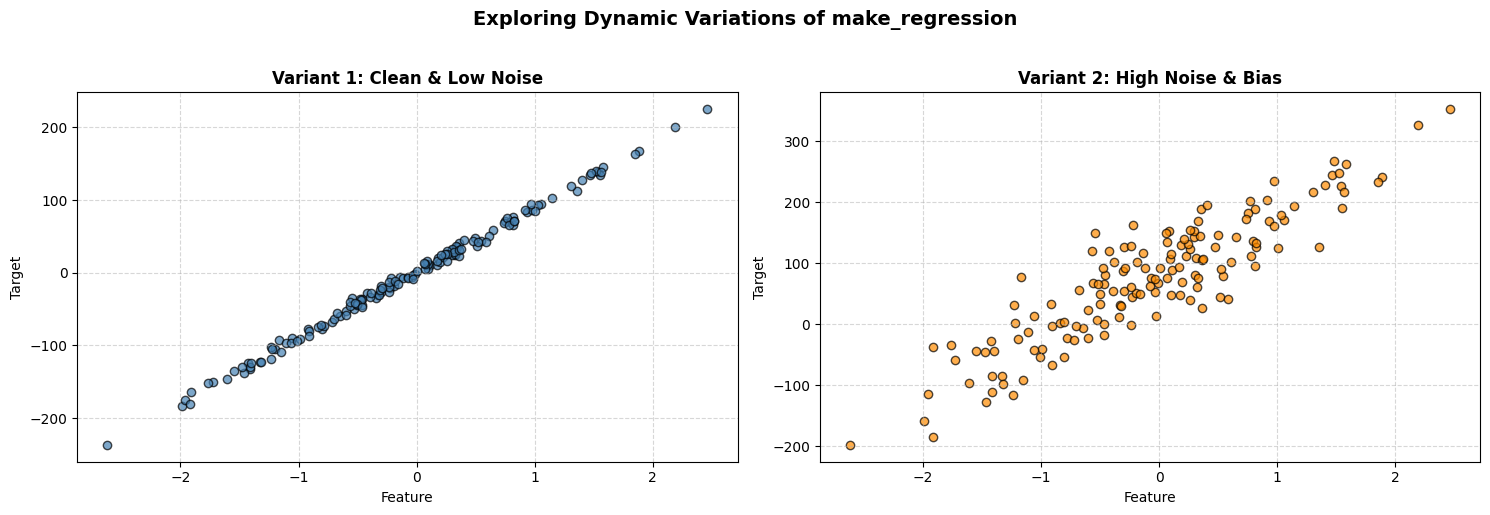

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression

# Set up a figure with 2 subplots to compare different variants
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# --- Variant 1: Clean & Simple (1 Feature, Low Noise) ---
X1, y1 = make_regression(n_samples=150, n_features=1, noise=5.0,bias=0.0, n_informative=1, random_state=42)
axes[0].scatter(X1, y1, color='steelblue', alpha=0.7, edgecolor='k')
axes[0].set_title("Variant 1: Clean & Low Noise", fontweight='bold')
axes[0].set_xlabel("Feature")
axes[0].set_ylabel("Target")
axes[0].grid(True, linestyle='--', alpha=0.5)

# --- Variant 2: High Noise & High Bias (Messier Data) ---
X2, y2 = make_regression(n_samples=150, n_features=1, noise=45.0, bias=75.0, n_informative=1, random_state=42)
axes[1].scatter(X2, y2, color='darkorange', alpha=0.7, edgecolor='k')
axes[1].set_title("Variant 2: High Noise & Bias", fontweight='bold')
axes[1].set_xlabel("Feature")
axes[1].set_ylabel("Target")
axes[1].grid(True, linestyle='--', alpha=0.5)


plt.suptitle("Exploring Dynamic Variations of make_regression", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## non-linear patterns with polynomial equation




<>:23: SyntaxWarning: invalid escape sequence '\s'
<>:27: SyntaxWarning: invalid escape sequence '\s'
<>:23: SyntaxWarning: invalid escape sequence '\s'
<>:27: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1041/3229834781.py:23: SyntaxWarning: invalid escape sequence '\s'
  axes[i].scatter(X_base, y_noisy, color='hotpink', alpha=0.7, edgecolor='k', label=f'Noise ($\sigma$={noise_std})')
/tmp/ipykernel_1041/3229834781.py:27: SyntaxWarning: invalid escape sequence '\s'
  axes[i].set_title(f"Noise Level: $\sigma$ = {noise_std}", fontweight='bold')


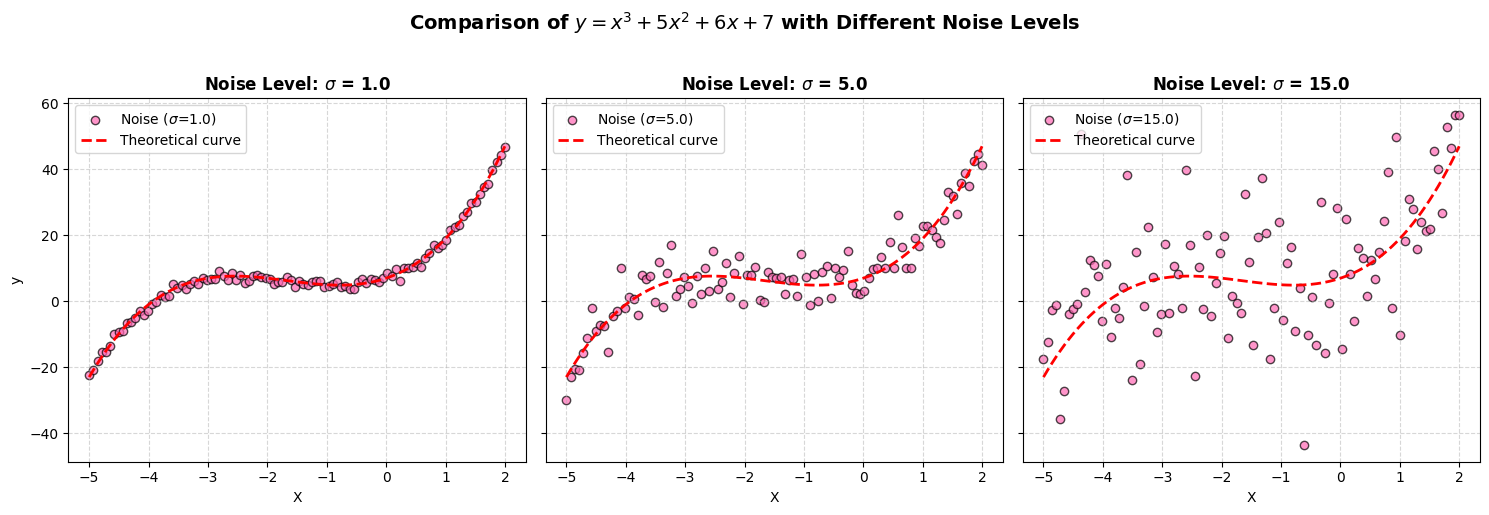

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Set random seed to ensure reproducibility
np.random.seed(42)

# Generate independent variable X and the clean base curve
X_base = np.linspace(-5, 2, 100)
y_clean = (X_base**3) + 5 * (X_base**2) + 6 * X_base + 7

# Define different noise standard deviations for comparison
noise_levels = [1.0, 5.0, 15.0]

# Set up subplots to compare different noise levels in one simple code
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)

for i, noise_std in enumerate(noise_levels):
    # Generate unique Gaussian noise for this level
    noise = np.random.normal(0, noise_std, size=X_base.shape)
    y_noisy = y_clean + noise

    # Scatter plot for noisy data
    axes[i].scatter(X_base, y_noisy, color='hotpink', alpha=0.7, edgecolor='k', label=f'Noise ($\sigma$={noise_std})')
    # Line plot for theoretical underlying curve
    axes[i].plot(X_base, y_clean, color='red', linestyle='--', linewidth=2, label='Theoretical curve')

    axes[i].set_title(f"Noise Level: $\sigma$ = {noise_std}", fontweight='bold')
    axes[i].set_xlabel("X")
    if i == 0:
        axes[i].set_ylabel("y")
    axes[i].legend(loc='upper left')
    axes[i].grid(True, linestyle='--', alpha=0.5)

plt.suptitle(r"Comparison of $y = x^3 + 5x^2 + 6x + 7$ with Different Noise Levels", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()